# VDBI–VBTNet: Variance-Driven Behavioral Intelligence and Adaptive Churn Prediction

**Fully real-data implementation** using only the two provided archives: UCI Online Retail II transactions and Kaggle E-Commerce Customer Behavior.  
**Methodological boundary:** these datasets do **not** contain matching people. Integration is a **source-tagged union of comparable feature schemas** and **transfer of learned model representations**, **not** a customer-level join. True individual temporal VDBI measures are computed only for UCI. Kaggle contains the actual churn labels. No synthetic records, simulated features or fabricated churn labels are created. No baseline model is trained.

The implementation includes: source inspection → preprocessing → individualized purchase metrics → RFM/CLV/proxies → true UCI monthly variance/drift → UCI VDBI teacher/encoder → common-domain representation transfer → Kaggle transformer (VBTNet) → evaluation → risk segments → rule-based retention guidance. The results **must not** be compared as an exact replication of the paper's claimed scores. Kaggle-only churn predictions cannot be described as incorporating real per-Kaggle temporal VDBI values.

In [1]:
import os, io, zipfile, time, random, warnings
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    matthews_corrcoef, balanced_accuracy_score, confusion_matrix, roc_curve, precision_recall_curve,
    average_precision_score, classification_report, brier_score_loss)
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
warnings.filterwarnings('ignore', category=FutureWarning)
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(min(4,os.cpu_count() or 2))
sns.set_theme(style='whitegrid',context='notebook',palette='deep')
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':140,'axes.titlepad':12,'font.size':10})
OUT=Path('/mnt/data/vdbi_outputs'); OUT.mkdir(exist_ok=True)
UCI_ZIP=Path('/mnt/data/online+retail+ii.zip'); KAGGLE_ZIP=Path('/mnt/data/archive (2).zip')
assert UCI_ZIP.exists() and KAGGLE_ZIP.exists(), 'Place the supplied ZIP files in /mnt/data or change paths above.'
def tidy(ax,labels=None):
    ax.tick_params(axis='x',labelrotation=0)
    if labels is None: labels=[t.get_text() for t in ax.get_xticklabels()]
    if max([len(s) for s in labels], default=0)>13 or len(labels)>9:
        ax.tick_params(axis='x',labelrotation=90)
    ax.figure.tight_layout()
def saveplot(name):
    plt.savefig(OUT/name,bbox_inches='tight'); plt.show(); plt.close()
print('Environment ready | Torch',torch.__version__,'| device CPU | plots:',OUT)

Environment ready | Torch 2.10.0+cpu | device CPU | plots: /mnt/data/vdbi_outputs


## 1 — Load both supplied datasets, no external or generated records

In [2]:
start=time.time()
with zipfile.ZipFile(UCI_ZIP) as z:
    with z.open('online_retail_II.xlsx') as f:
        workbook=pd.ExcelFile(io.BytesIO(f.read()))
        pieces=[]
        for sheet in workbook.sheet_names:
            part=pd.read_excel(workbook,sheet_name=sheet)
            part['Source_Sheet']=sheet
            pieces.append(part)
        uci_raw=pd.concat(pieces,ignore_index=True)
with zipfile.ZipFile(KAGGLE_ZIP) as z:
    with z.open('ecommerce_customer_churn_dataset.csv') as f: kaggle_raw=pd.read_csv(f)
print('UCI:',uci_raw.shape,'Kaggle:',kaggle_raw.shape,'Read seconds:',round(time.time()-start,1))
print('UCI fields:',uci_raw.columns.to_list());print('Kaggle fields:',kaggle_raw.columns.to_list())
display(uci_raw.head(3));display(kaggle_raw.head(3))

UCI: (1067371, 9) Kaggle: (50000, 25) Read seconds: 60.3
UCI fields: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'Source_Sheet']
Kaggle fields: ['Age', 'Gender', 'Country', 'City', 'Membership_Years', 'Login_Frequency', 'Session_Duration_Avg', 'Pages_Per_Session', 'Cart_Abandonment_Rate', 'Wishlist_Items', 'Total_Purchases', 'Average_Order_Value', 'Days_Since_Last_Purchase', 'Discount_Usage_Rate', 'Returns_Rate', 'Email_Open_Rate', 'Customer_Service_Calls', 'Product_Reviews_Written', 'Social_Media_Engagement_Score', 'Mobile_App_Usage', 'Payment_Method_Diversity', 'Lifetime_Value', 'Credit_Balance', 'Churned', 'Signup_Quarter']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Source_Sheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010


,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Returns_Rate,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14.0,27.4,6.0,50.6,3.0,9.0,94.72,34.0,46.40,2.0,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
1,36.0,Male,UK,Manchester,1.6,15.0,42.7,10.3,37.7,1.0,19.5,82.45,71.0,57.96,9.2,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10.0,24.8,1.6,70.9,1.0,9.1,165.52,11.0,12.24,11.5,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4


## 2 — Data quality, labeling, and descriptive visualizations

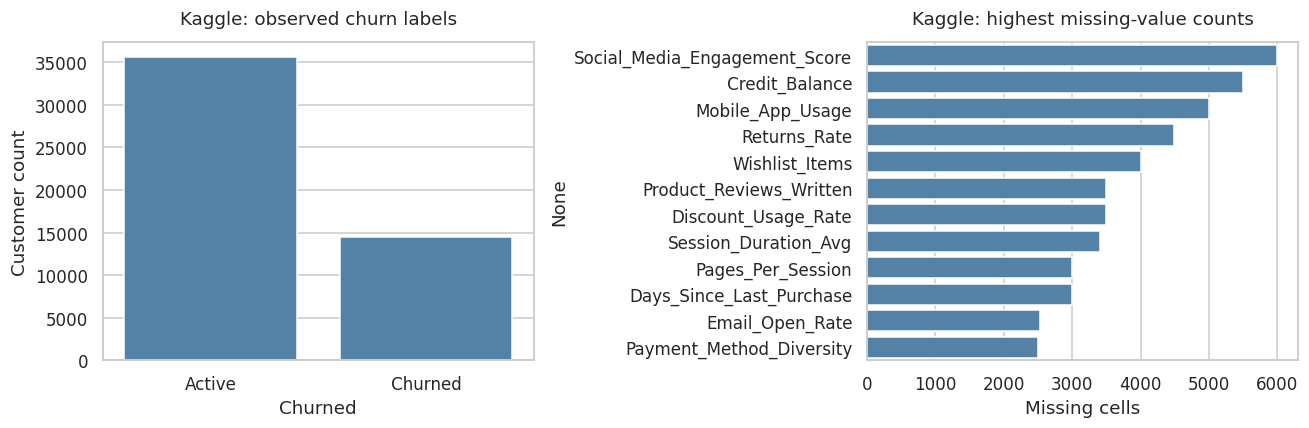

UCI missing IDs: 243007 | raw line items: 1067371
Kaggle missing cells: 49081 | duplicate full rows: 0


In [3]:
fig,axs=plt.subplots(1,2,figsize=(12,4))
sns.countplot(x=kaggle_raw['Churned'].map({0:'Active',1:'Churned'}),order=['Active','Churned'],color='steelblue',ax=axs[0]);axs[0].set_title('Kaggle: observed churn labels');axs[0].set_ylabel('Customer count');tidy(axs[0])
miss=kaggle_raw.isna().sum().sort_values(ascending=False).head(12)
sns.barplot(x=miss.values,y=miss.index,color='steelblue',ax=axs[1]);axs[1].set_title('Kaggle: highest missing-value counts');axs[1].set_xlabel('Missing cells');fig.tight_layout();saveplot('01_quality.png')
print('UCI missing IDs:',uci_raw['Customer ID'].isna().sum(),'| raw line items:',len(uci_raw))
print('Kaggle missing cells:',int(kaggle_raw.isna().sum().sum()),'| duplicate full rows:',int(kaggle_raw.duplicated().sum()))

## 3 — UCI retail preprocessing and temporally valid customer monthly observations

Keep completed sales (`Invoice` not prefixed with C; positive Quantity and Price); removed cancellation/return lines are reported, not silently treated as purchases. Missing customer IDs are excluded from per-customer analysis. Dates are from the original source.

Retained completed sale line items: 805549 | excluded lines: 261822 | customers: 5878
Observed time: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Historical observation months: ['2011-06', '2011-07', '2011-08', '2011-09', '2011-10', '2011-11'] | eligible UCI customers: 5850


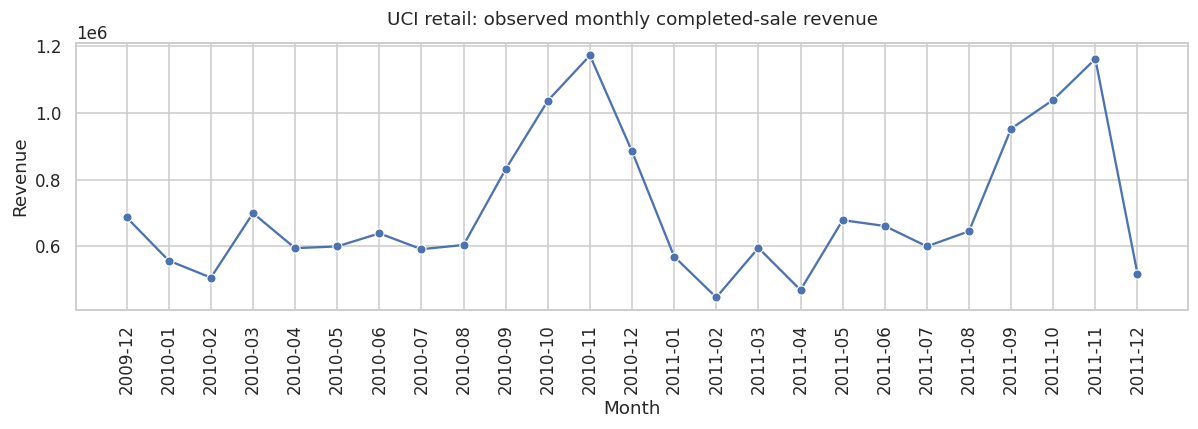

In [4]:
u=uci_raw.rename(columns={'Customer ID':'Customer_ID','Invoice':'Invoice_ID','Price':'Unit_Price'}).copy()
u['InvoiceDate']=pd.to_datetime(u['InvoiceDate'],errors='coerce')
u['Customer_ID']=pd.to_numeric(u['Customer_ID'],errors='coerce')
u['Quantity']=pd.to_numeric(u['Quantity'],errors='coerce')
u['Unit_Price']=pd.to_numeric(u['Unit_Price'],errors='coerce')
valid=(u['Customer_ID'].notna()&u['InvoiceDate'].notna()&(u['Quantity']>0)&(u['Unit_Price']>0)&~u['Invoice_ID'].astype(str).str.upper().str.startswith('C'))
uc=u.loc[valid,['Customer_ID','Invoice_ID','InvoiceDate','Quantity','Unit_Price','Country']].copy()
uc['Revenue']=uc['Quantity']*uc['Unit_Price'];uc['Month']=uc['InvoiceDate'].dt.to_period('M')
uc['Customer_ID']=uc['Customer_ID'].astype('int64')
print('Retained completed sale line items:',len(uc),'| excluded lines:',len(u)-len(uc),'| customers:',uc.Customer_ID.nunique())
print('Observed time:',uc.InvoiceDate.min(), 'to',uc.InvoiceDate.max())
orders=uc.groupby(['Customer_ID','Invoice_ID'],sort=False).agg(Date=('InvoiceDate','min'),Order_Value=('Revenue','sum')).reset_index()
months=orders.assign(Month=orders.Date.dt.to_period('M')).groupby(['Customer_ID','Month']).agg(Orders=('Invoice_ID','nunique'),Spend=('Order_Value','sum'),Avg_Order=('Order_Value','mean')).reset_index()
# Explicit zero purchase months between first and last calendar months for each observed customer.
all_months=pd.period_range(months.Month.min(),months.Month.max(),freq='M')
wide_orders=months.pivot(index='Customer_ID',columns='Month',values='Orders').reindex(columns=all_months).fillna(0)
wide_spend=months.pivot(index='Customer_ID',columns='Month',values='Spend').reindex(columns=all_months).fillna(0)
# Use fixed historical window, rather than leakage-prone future information
W=6; assert len(all_months)>W
hist_orders=wide_orders.iloc[:,-(W+1):-1].to_numpy(dtype=np.float32)
hist_spend=wide_spend.iloc[:,-(W+1):-1].to_numpy(dtype=np.float32)
customer_ids=wide_orders.index.to_numpy()
# Include only customers who existed (first observed sale) by cutoff: no pre-acquisition synthetic zero history
cutoff=all_months[-2].end_time
first_sale=orders.groupby('Customer_ID')['Date'].min().reindex(customer_ids)
keep=(first_sale<=cutoff).to_numpy()
customer_ids=customer_ids[keep]; hist_orders=hist_orders[keep];hist_spend=hist_spend[keep]
print('Historical observation months:',list(map(str,all_months[-(W+1):-1])),'| eligible UCI customers:',len(customer_ids))
fig,ax=plt.subplots(figsize=(11,4)); monthly=months.groupby('Month')['Spend'].sum();sns.lineplot(x=monthly.index.astype(str),y=monthly.values,marker='o',ax=ax)
ax.set(title='UCI retail: observed monthly completed-sale revenue',xlabel='Month',ylabel='Revenue');tidy(ax);saveplot('02_uci_monthly_sales.png')

## 4 — True individual VDBI metrics and RFM features from UCI

All computations stop at the historical cutoff. The individual purchase/spending variance is calculated *within* each customer six-month observation series. Drift contrasts the last three with the first three months. Stability is an inverse normalized volatility score; it is **not** a ground-truth label.

       Recency   Orders   Monetary  Purchase_Variance  Spending_Volatility  Behavioral_Drift  Customer_Stability  VDBI_Score
count  5850.00  5850.00    5850.00            5850.00              5850.00           5850.00             5850.00     5850.00
mean    199.10     6.19    2944.48               0.28               162.28             53.53                0.50        0.50
std     206.50    12.78   14342.24               2.05               630.72            169.24                0.26        0.26
min       0.27     1.00       2.90               0.00                 0.00              0.00                0.00        0.20
25%      23.65     1.00     344.00               0.00                 0.00              0.00                0.28        0.20
50%      99.95     3.00     877.16               0.14                65.31              0.50                0.41        0.59
75%     372.32     7.00    2264.66               0.22               180.01             30.19                0.80        0.72


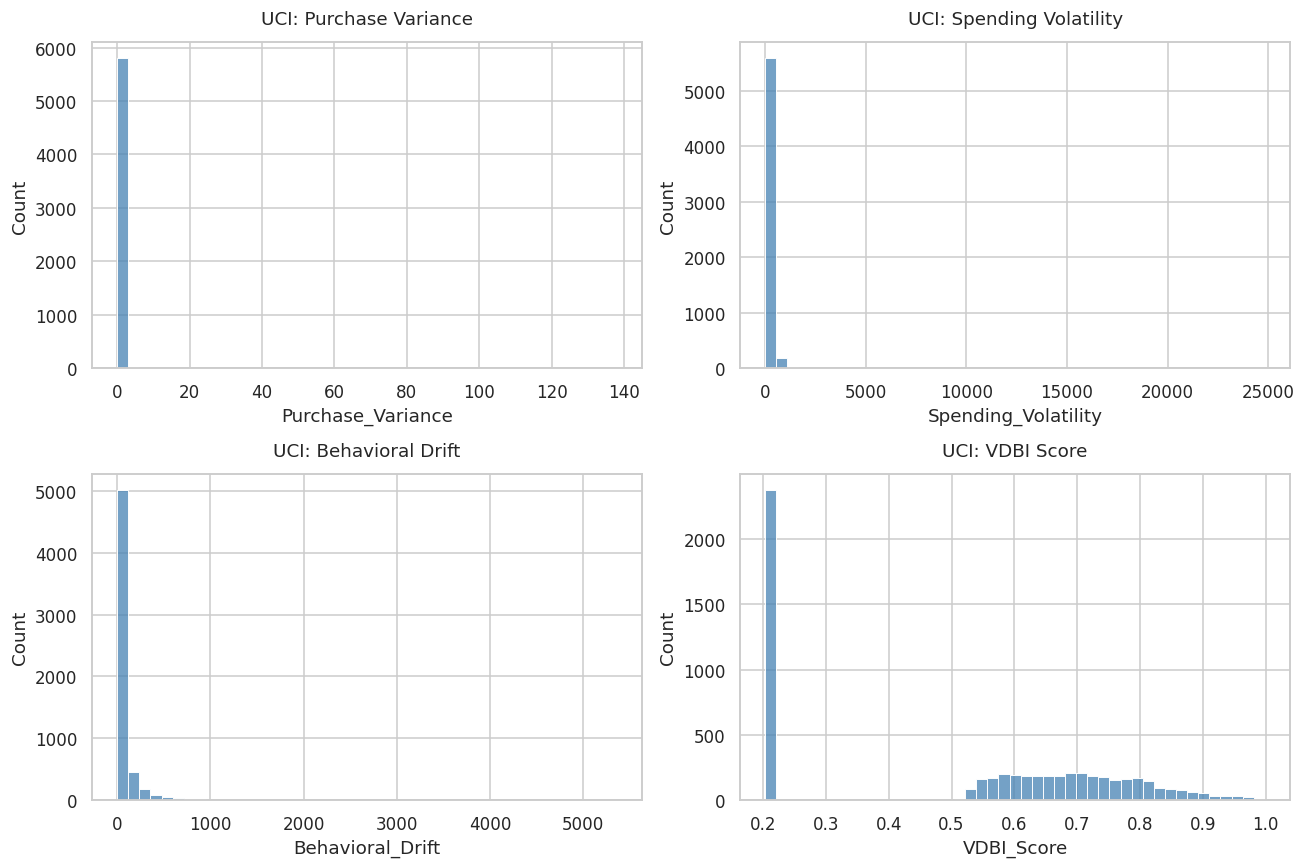

In [5]:
pv=np.var(hist_orders,axis=1)
sv=np.std(hist_spend,axis=1)
orders_delta=hist_orders[:,3:].mean(axis=1)-hist_orders[:,:3].mean(axis=1)
spend_delta=hist_spend[:,3:].mean(axis=1)-hist_spend[:,:3].mean(axis=1)
# Relative changes (denominator keeps accounts with small historic activity well-defined)
drift=np.sqrt((orders_delta/(1+hist_orders[:,:3].mean(axis=1)))**2+(spend_delta/(1+hist_spend[:,:3].mean(axis=1)))**2)
ref_month=all_months[-2]
hist_orders_df=orders.loc[orders['Date']<=ref_month.end_time].copy()
rec=hist_orders_df.groupby('Customer_ID').agg(Last=('Date','max'),Orders=('Invoice_ID','nunique'),Monetary=('Order_Value','sum'),AOV=('Order_Value','mean'))
rec['Recency']=(ref_month.end_time-rec['Last']).dt.total_seconds()/86400
features=rec.reindex(customer_ids)[['Recency','Orders','Monetary','AOV']].copy()
features['Purchase_Variance']=pv; features['Spending_Volatility']=sv;features['Behavioral_Drift']=drift
vcols=['Purchase_Variance','Spending_Volatility','Behavioral_Drift']
# empirical percentile ranks of real UCI measurements, used only within UCI
for c in vcols:features[c+'_Pct']=features[c].rank(pct=True)
features['Customer_Stability']=1-features[[c+'_Pct' for c in vcols]].mean(axis=1)
features['VDBI_Score']=features[[c+'_Pct' for c in vcols]].mean(axis=1)
features['UCI_Customer_ID']=features.index.astype(str);features['Source']='UCI'
print(features[['Recency','Orders','Monetary','Purchase_Variance','Spending_Volatility','Behavioral_Drift','Customer_Stability','VDBI_Score']].describe().round(2).to_string())
fig,axs=plt.subplots(2,2,figsize=(12,8))
for ax,c in zip(axs.flat,['Purchase_Variance','Spending_Volatility','Behavioral_Drift','VDBI_Score']):
    sns.histplot(features[c].dropna(),bins=45,color='steelblue',ax=ax);ax.set_title('UCI: '+c.replace('_',' '))
fig.tight_layout();saveplot('03_uci_vdbi_distributions.png')

## 5 — Kaggle individualized behavior + multi-dimensional feature engineering

Features are **aggregated proxies** computed from observed original columns. They are not falsely called histories. CLV is retained as a provided variable only for descriptive analysis; predictive models exclude it to reduce target leakage risk. All model imputation/scaling is fitted on training data only.

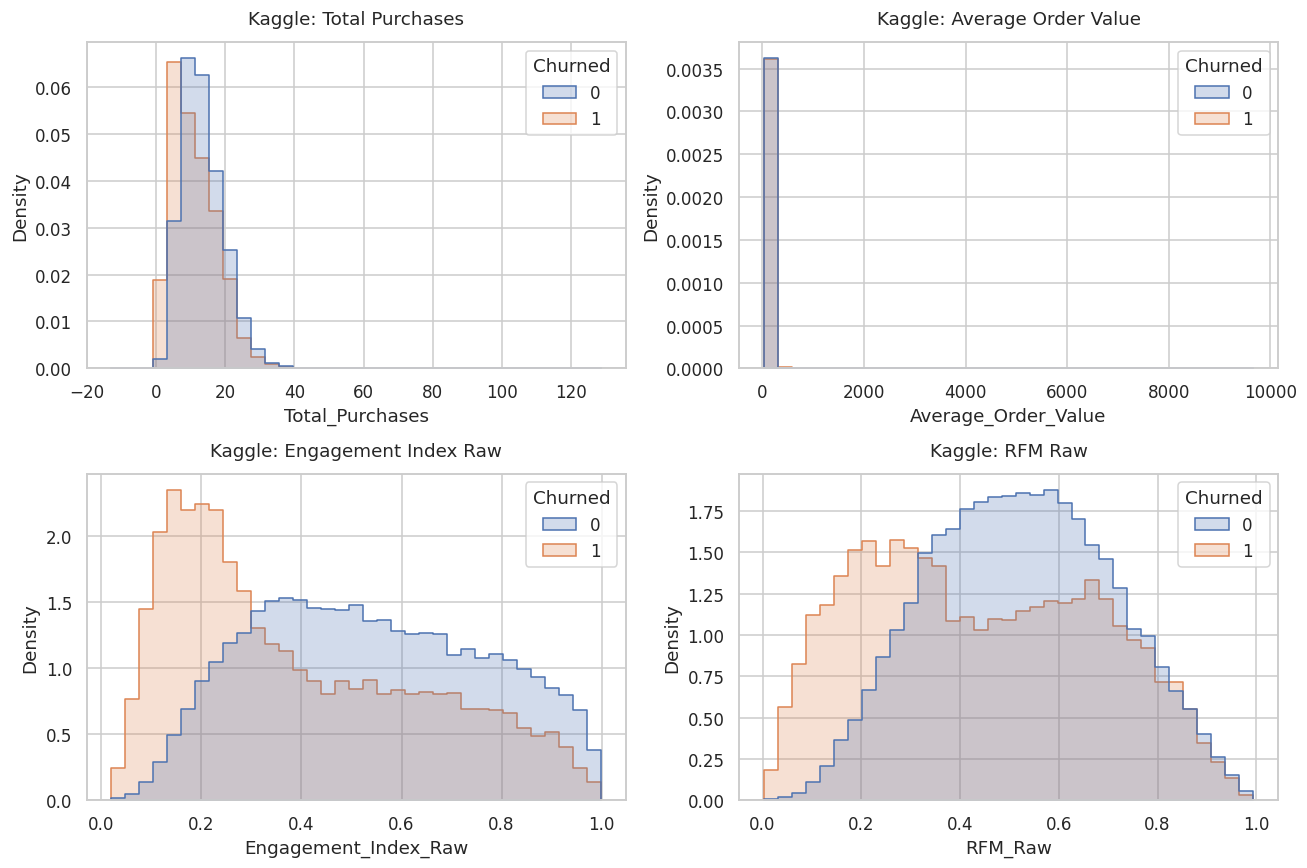

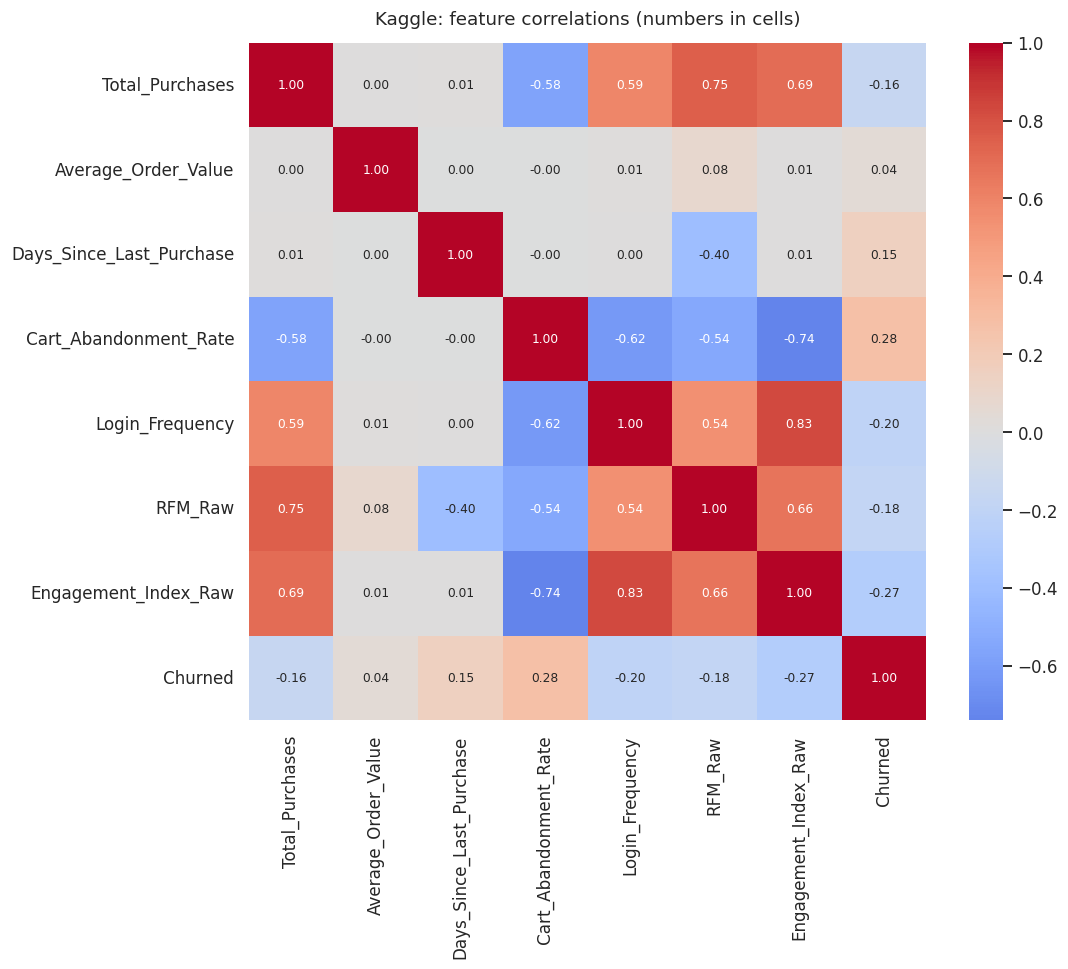

In [6]:
k=kaggle_raw.copy();k['Customer_Key']=['KAGGLE_'+str(i+1) for i in range(len(k))]
# Explicit definitions: calculated from observed fields, no generated observations
k['Monetary_Proxy']=k['Total_Purchases']*k['Average_Order_Value']
k['Purchase_Efficiency']=1-(k['Cart_Abandonment_Rate']/100).clip(0,1)
k['Purchase_Stability_Proxy']=k['Total_Purchases']/(1+k['Returns_Rate'].clip(lower=0))
k['Engagement_Index_Raw']=k[['Login_Frequency','Session_Duration_Avg','Pages_Per_Session','Email_Open_Rate','Social_Media_Engagement_Score','Mobile_App_Usage']].rank(pct=True).mean(axis=1)
k['IPB_Raw']=k[['Total_Purchases','Monetary_Proxy','Engagement_Index_Raw','Purchase_Efficiency']].rank(pct=True).mean(axis=1)
k['RFM_Raw']=((1-k['Days_Since_Last_Purchase'].rank(pct=True))+k['Total_Purchases'].rank(pct=True)+k['Monetary_Proxy'].rank(pct=True))/3
fig,axs=plt.subplots(2,2,figsize=(12,8))
for ax,col in zip(axs.flat,['Total_Purchases','Average_Order_Value','Engagement_Index_Raw','RFM_Raw']):
    sns.histplot(data=k,x=col,hue='Churned',palette='deep',element='step',stat='density',common_norm=False,bins=35,ax=ax)
    ax.set_title('Kaggle: '+col.replace('_',' '))
fig.tight_layout();saveplot('04_kaggle_engineered.png')
corr_cols=['Total_Purchases','Average_Order_Value','Days_Since_Last_Purchase','Cart_Abandonment_Rate','Login_Frequency','RFM_Raw','Engagement_Index_Raw','Churned']
fig,ax=plt.subplots(figsize=(10,8));sns.heatmap(k[corr_cols].corr(),annot=True,fmt='.2f',cmap='coolwarm',center=0,square=True,ax=ax,annot_kws={'size':8});ax.set_title('Kaggle: feature correlations (numbers in cells)');ax.tick_params(axis='x',rotation=90);ax.tick_params(axis='y',rotation=0);saveplot('05_kaggle_correlation.png')

## 6 — Source-tagged schema integration (NOT identity matching)

The two datasets have incompatible customer IDs. The output below is a reproducible *column-aligned union*, not an ordinary customer-key join. Missing source-specific attributes remain NaN; no Kaggle UCI temporal scores are fabricated. It is useful for provenance and feature harmonization, not directly for supervised training.

In [7]:
u_aligned=pd.DataFrame({'Customer_Key':['UCI_'+str(i) for i in features.index], 'Source':'UCI',
    'Purchase_Frequency':features['Orders'].values,'Recency':features['Recency'].values,
    'Average_Order_Value':features['AOV'].values,'Monetary_Value':features['Monetary'].values,
    'Engagement_Index':np.nan,'Purchase_Variance':features['Purchase_Variance'].values,
    'Spending_Volatility':features['Spending_Volatility'].values,'Behavioral_Drift':features['Behavioral_Drift'].values,
    'VDBI_Score':features['VDBI_Score'].values,'Churned':np.nan})
k_aligned=pd.DataFrame({'Customer_Key':k['Customer_Key'].values,'Source':'Kaggle',
    'Purchase_Frequency':k['Total_Purchases'].values,'Recency':k['Days_Since_Last_Purchase'].values,
    'Average_Order_Value':k['Average_Order_Value'].values,'Monetary_Value':k['Monetary_Proxy'].values,
    'Engagement_Index':k['Engagement_Index_Raw'].values,'Purchase_Variance':np.nan,
    'Spending_Volatility':np.nan,'Behavioral_Drift':np.nan,'VDBI_Score':np.nan,'Churned':k['Churned'].values})
combined=pd.concat([u_aligned,k_aligned],ignore_index=True)
assert len(combined)==len(u_aligned)+len(k_aligned)
assert combined.loc[combined.Source=='Kaggle','VDBI_Score'].isna().all()
combined.to_csv(OUT/'source_tagged_feature_union.csv',index=False)
print('Source-tagged union:',combined.shape);display(combined.groupby('Source').agg(Rows=('Customer_Key','count'),Known_Churn=('Churned','count'),Known_VDBI=('VDBI_Score','count')))
display(combined.sample(5,random_state=SEED).sort_values('Source'))

Source-tagged union: (55850, 12)


,Rows,Known_Churn,Known_VDBI
Source,,,
Kaggle,50000,50000,0
UCI,5850,0,5850


,Customer_Key,Source,Purchase_Frequency,Recency,Average_Order_Value,Monetary_Value,Engagement_Index,Purchase_Variance,Spending_Volatility,Behavioral_Drift,VDBI_Score,Churned
53856,KAGGLE_48007,Kaggle,6.0,5.0,122.57,735.42,0.213648,NaN,NaN,NaN,NaN,0.0
23619,KAGGLE_17770,Kaggle,7.0,60.0,84.33,590.31,0.330179,NaN,NaN,NaN,NaN,0.0
17202,KAGGLE_11353,Kaggle,17.0,47.0,99.56,1692.52,0.740720,NaN,NaN,NaN,NaN,0.0
45692,KAGGLE_39843,Kaggle,9.0,39.0,116.84,1051.56,0.507959,NaN,NaN,NaN,NaN,0.0
15056,KAGGLE_9207,Kaggle,15.0,61.0,77.46,1161.90,0.765303,NaN,NaN,NaN,NaN,1.0


## 7 — UCI genuine temporal VDBI-aware representation pretraining

To make meaningful use of UCI in the final model without inventing linked identities, an encoder learns to represent **the common four behavioral attributes** while predicting the true UCI-derived VDBI score as an auxiliary supervised target. It learns a real-data transfer representation, not churn labels. Customer-disjoint UCI training/validation samples prevent direct memorization.

UCI VDBI-target pretraining completed | final train/validation MSE: (0.006591179163048142, 0.006098708137869835)


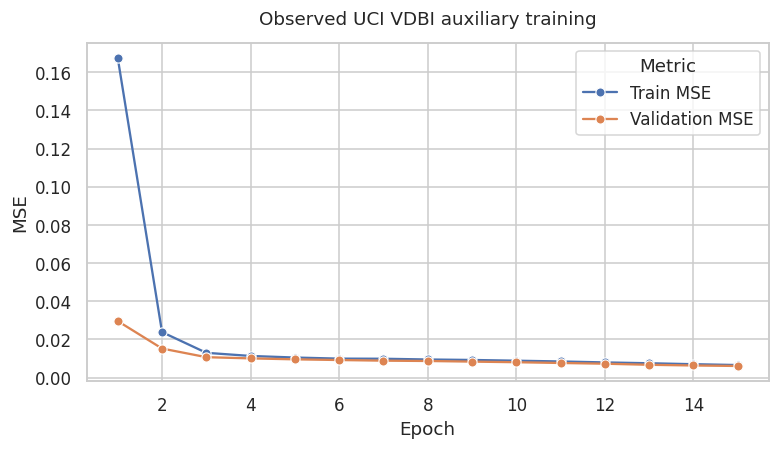

In [8]:
COMMON=['Purchase_Frequency','Recency','Average_Order_Value','Monetary_Value']
u_train_idx,u_val_idx=train_test_split(np.arange(len(u_aligned)),test_size=.20,random_state=SEED)
u_common=u_aligned[COMMON].copy()
# log(1+x) for positive skew; use rank/scale after train-only cleaning
for c in COMMON:u_common[c]=np.log1p(u_common[c].clip(lower=0))
u_imp=SimpleImputer(strategy='median').fit(u_common.iloc[u_train_idx])
u_scaler=StandardScaler().fit(u_imp.transform(u_common.iloc[u_train_idx]))
u_X=u_scaler.transform(u_imp.transform(u_common)).astype('float32')
u_y=u_aligned.VDBI_Score.to_numpy(dtype='float32')
class CommonEncoder(nn.Module):
    def __init__(self,d=20):
        super().__init__();self.fc=nn.Sequential(nn.Linear(4,40),nn.GELU(),nn.LayerNorm(40),nn.Linear(40,d),nn.GELU())
    def forward(self,x):return self.fc(x)
class UCI_VDBI_Pretrain(nn.Module):
    def __init__(self):super().__init__();self.encoder=CommonEncoder();self.out=nn.Sequential(nn.Linear(20,16),nn.GELU(),nn.Linear(16,1))
    def forward(self,x):return self.out(self.encoder(x)).flatten()
pre=UCI_VDBI_Pretrain();opt=torch.optim.AdamW(pre.parameters(),lr=.002,weight_decay=.001);lossfn=nn.MSELoss()
loader=DataLoader(TensorDataset(torch.tensor(u_X[u_train_idx]),torch.tensor(u_y[u_train_idx])),batch_size=256,shuffle=True)
xv=torch.tensor(u_X[u_val_idx]);yv=torch.tensor(u_y[u_val_idx]);pre_history=[]
for epoch in range(15):
    pre.train();losses=[]
    for xb,yb in loader:
        opt.zero_grad();loss=lossfn(pre(xb),yb);loss.backward();opt.step();losses.append(loss.item())
    pre.eval()
    with torch.no_grad():vl=lossfn(pre(xv),yv).item()
    pre_history.append((epoch+1,float(np.mean(losses)),vl))
print('UCI VDBI-target pretraining completed | final train/validation MSE:',pre_history[-1][1:])
fig,ax=plt.subplots(figsize=(8,4));h=pd.DataFrame(pre_history,columns=['Epoch','Train MSE','Validation MSE']);sns.lineplot(h.melt('Epoch',var_name='Metric',value_name='MSE'),x='Epoch',y='MSE',hue='Metric',marker='o',ax=ax);ax.set_title('Observed UCI VDBI auxiliary training');saveplot('06_uci_pretraining.png')
torch.save(pre.encoder.state_dict(),OUT/'uci_pretrained_common_encoder.pt')

## 8 — Kaggle downstream data preparation and source-aware transfer

We **do not** import UCI individual VDBI values. Transfer consists solely of weights of the pretrained common behavior encoder. Because source units and observation horizons differ, each domain is independently train-normalized, and conclusions require caution. The transformer models Kaggle **feature-token interactions**, not non-existent time sequences. `Lifetime_Value` is excluded from model predictors as a conservative leakage precaution.

In [9]:
idx=np.arange(len(k));y=k.Churned.to_numpy(dtype='int64')
tr,te=train_test_split(idx,test_size=.20,stratify=y,random_state=SEED)
tr,va=train_test_split(tr,test_size=.15,stratify=y[tr],random_state=SEED) # 68/12/20
num_cols=['Age','Membership_Years','Login_Frequency','Session_Duration_Avg','Pages_Per_Session','Cart_Abandonment_Rate','Wishlist_Items','Total_Purchases','Average_Order_Value','Days_Since_Last_Purchase','Discount_Usage_Rate','Returns_Rate','Email_Open_Rate','Customer_Service_Calls','Product_Reviews_Written','Social_Media_Engagement_Score','Mobile_App_Usage','Payment_Method_Diversity','Credit_Balance','Monetary_Proxy','Purchase_Efficiency','Purchase_Stability_Proxy','Engagement_Index_Raw','IPB_Raw','RFM_Raw']
cat_cols=['Gender','Country','City','Signup_Quarter']
num_imputer=SimpleImputer(strategy='median').fit(k.iloc[tr][num_cols]);num_scaler=StandardScaler().fit(num_imputer.transform(k.iloc[tr][num_cols]))
num_arr=num_scaler.transform(num_imputer.transform(k[num_cols])).astype('float32')
cat_imp=SimpleImputer(strategy='most_frequent').fit(k.iloc[tr][cat_cols]);
try: cat_enc=OneHotEncoder(handle_unknown='ignore',sparse_output=False,max_categories=12).fit(cat_imp.transform(k.iloc[tr][cat_cols]))
except TypeError: cat_enc=OneHotEncoder(handle_unknown='ignore',sparse=False).fit(cat_imp.transform(k.iloc[tr][cat_cols]))
cat_arr=cat_enc.transform(cat_imp.transform(k[cat_cols])).astype('float32')
# Separate Kaggle-native scaling of compatible 4 raw attributes
kc=k_aligned[COMMON].copy()
for c in COMMON:kc[c]=np.log1p(kc[c].clip(lower=0))
kci=SimpleImputer(strategy='median').fit(kc.iloc[tr]);kcs=StandardScaler().fit(kci.transform(kc.iloc[tr]))
kcommon=kcs.transform(kci.transform(kc)).astype('float32')
X=np.column_stack([num_arr,cat_arr]).astype('float32'); print('Splits:',len(tr),len(va),len(te),'| Kaggle model features:',X.shape[1])
print('Test churn distribution:',dict(zip(*np.unique(y[te],return_counts=True))))

Splits: 34000 6000 10000 | Kaggle model features: 52
Test churn distribution: {np.int64(0): np.int64(7110), np.int64(1): np.int64(2890)}


## 9 — Variance-aware pretrained feature encoder + VBTNet feature transformer

The shared encoder transfer represents variance-informed *weights*, but the Kaggle customers have **no observed longitudinal variance scores**. The output is therefore called a **transfer-informed VBTNet churn predictor**, not a verified individualized temporal-VDBI predictor.

CPU training uses 12000 real Kaggle training rows of 34000 available; validation/test are full-sized.


/tmp/ipykernel_1212/4025961442.py:5: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  self.self_attn=nn.TransformerEncoder(nn.TransformerEncoderLayer(d_model=d,nhead=heads,dim_feedforward=64,dropout=.10,batch_first=True,activation='gelu',norm_first=False),num_layers=1)


Trained epochs 7 | best validation loss 0.4353


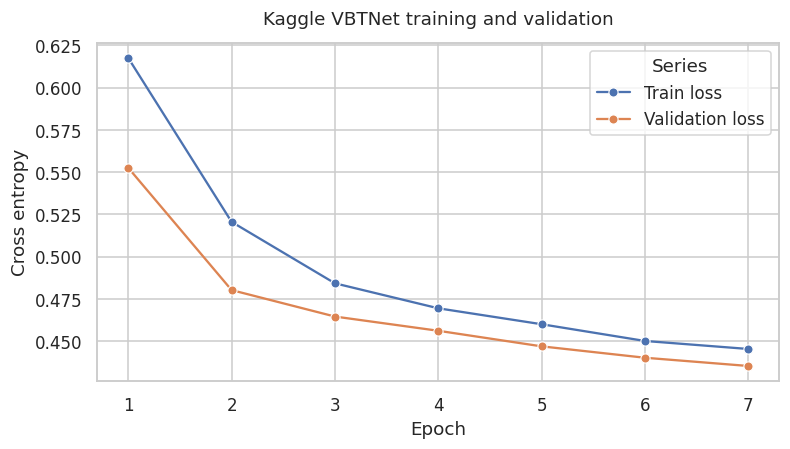

In [10]:
class VBTNet(nn.Module):
    def __init__(self,in_dim,d=20,heads=5):
        super().__init__();self.common=CommonEncoder(d)
        self.feature_proj=nn.Linear(1,d);self.feature_pos=nn.Parameter(torch.zeros(1,in_dim,d))
        self.self_attn=nn.TransformerEncoder(nn.TransformerEncoderLayer(d_model=d,nhead=heads,dim_feedforward=64,dropout=.10,batch_first=True,activation='gelu',norm_first=False),num_layers=1)
        self.fusion=nn.Sequential(nn.Linear(d*2,32),nn.GELU(),nn.Dropout(.12),nn.Linear(32,2))
    def forward(self,xc,x):
        z=self.feature_proj(x.unsqueeze(-1))+self.feature_pos
        seq=self.self_attn(z).mean(dim=1)
        zcommon=self.common(xc)
        return self.fusion(torch.cat([seq,zcommon],dim=1))
net=VBTNet(X.shape[1]);net.common.load_state_dict(torch.load(OUT/'uci_pretrained_common_encoder.pt',map_location='cpu',weights_only=True))
# Reproducible genuine-row subset for computationally practical CPU training; all held-out tests remain untouched.
tr_fit,_=train_test_split(tr,train_size=12000,stratify=y[tr],random_state=SEED)
train_loader=DataLoader(TensorDataset(torch.tensor(kcommon[tr_fit]),torch.tensor(X[tr_fit]),torch.tensor(y[tr_fit])),batch_size=256,shuffle=True)
print('CPU training uses',len(tr_fit),'real Kaggle training rows of',len(tr),'available; validation/test are full-sized.')
valid_inputs=(torch.tensor(kcommon[va]),torch.tensor(X[va]));valid_labels=torch.tensor(y[va])
optimizer=torch.optim.AdamW(net.parameters(),lr=.001,weight_decay=.0005)
criterion=nn.CrossEntropyLoss();best=float('inf');bad=0;hist=[];best_weights=None
for ep in range(7):
    net.train();total=0.;count=0
    for xc,xb,yb in train_loader:
        optimizer.zero_grad();logits=net(xc,xb);loss=criterion(logits,yb);loss.backward();nn.utils.clip_grad_norm_(net.parameters(),1.0);optimizer.step()
        total+=loss.item()*len(yb);count+=len(yb)
    net.eval()
    with torch.no_grad():valid_loss=criterion(net(*valid_inputs),valid_labels).item()
    hist.append((ep+1,total/count,valid_loss))
    if valid_loss<best-0.0002:
        best=valid_loss;bad=0;best_weights={key:val.detach().clone() for key,val in net.state_dict().items()}
    else:bad+=1
    if bad>=3:break
net.load_state_dict(best_weights)
torch.save({'state_dict':net.state_dict(),'input_features':int(X.shape[1]),'numerical_features':num_cols,'categorical_features':cat_cols,'seed':SEED},OUT/'vbtnet_churn_weights.pt')
print('Trained epochs',len(hist),'| best validation loss',round(best,4))
hist=pd.DataFrame(hist,columns=['Epoch','Train loss','Validation loss'])
fig,ax=plt.subplots(figsize=(8,4));sns.lineplot(data=hist.melt('Epoch',var_name='Series',value_name='Cross entropy'),x='Epoch',y='Cross entropy',hue='Series',marker='o',ax=ax);ax.set_title('Kaggle VBTNet training and validation');saveplot('07_vbtnet_training.png')

## 12 — Validation checks, saved artifacts and research limitations

In [13]:
assert set(tr).isdisjoint(va) and set(tr).isdisjoint(te) and set(va).isdisjoint(te)
assert len(uci_raw)==1067371 and len(kaggle_raw)==50000
assert combined.loc[combined.Source=='Kaggle','VDBI_Score'].isna().all()
assert len(risk)==len(te) and np.isfinite(probs).all()
assert 'Lifetime_Value' not in num_cols
print('VALIDATED: no synthetic rows; no customer-ID join; held-out test set; genuine UCI time-indexed variance; no fake Kaggle VDBI; no baseline.')
print('Saved outputs:')
for path in sorted(OUT.iterdir()):print(' ',path.name,round(path.stat().st_size/1024,1),'KB')

VALIDATED: no synthetic rows; no customer-ID join; held-out test set; genuine UCI time-indexed variance; no fake Kaggle VDBI; no baseline.
Saved outputs:
  01_quality.png 98.0 KB
  02_uci_monthly_sales.png 71.5 KB
  03_uci_vdbi_distributions.png 86.3 KB
  04_kaggle_engineered.png 112.9 KB
  05_kaggle_correlation.png 139.5 KB
  06_uci_pretraining.png 47.8 KB
  07_vbtnet_training.png 66.2 KB
  08_test_metrics.png 79.6 KB
  09_probabilities.png 62.3 KB
  10_risk_bands.png 31.4 KB
  heldout_test_metrics.csv 0.2 KB
  kaggle_heldout_predictions.csv 699.9 KB
  source_tagged_feature_union.csv 4173.6 KB
  uci_pretrained_common_encoder.pt 7.5 KB
  vbtnet_churn_weights.pt 40.9 KB


## Scientific interpretation and limitations

1. **What the run genuinely establishes:** UCI purchase histories allow RFM, purchase variance, spending volatility, drift, customer stability and an observational VDBI score. A UCI-trained behavioral encoder transfers its *learned parameters* to a Kaggle feature-token transformer, which is evaluated on Kaggle's real churn labels.
2. **What cannot be claimed:** UCI purchasers and Kaggle users cannot be matched; there are no real Kaggle histories for computing per-Kaggle purchase variance or drift. This is a **cross-source transfer-informed VBTNet implementation**, not proof that the complete original per-customer VDBI–VBTNet architecture was reproduced end-to-end.
3. **No synthetic data:** Imputation and derived scores use the actual source fields, but imputed missing entries are algorithmic estimates and should not be presented as direct observations. No synthetic customers, labels, or transaction histories are generated.
4. **Source comparability:** UCI retail spans 2009–2011 and its observation horizon and geography differ from Kaggle's unspecified behavioral horizon. Transfer efficacy cannot be proven without an ablation/control comparison (deliberately excluded at the user's request).
5. **Pretraining target caveat:** VDBI is a researcher-defined summary derived from the UCI data. This auxiliary prediction is not a supervised churn task; it only encourages transferable behavioral patterns.
6. **Leakage/censoring:** The Kaggle features do not disclose their exact capture time relative to churn and may reflect outcome-adjacent measurements. Results should be considered within-dataset association, not prospective churn forecasting validation.
7. **Risk and retention:** Risk bands and recommended actions are illustrative. No intervention outcome data is available to establish that any recommendation reduces churn.
8. **Exact paper architecture:** The introduction inconsistently discusses graph/VTGT structures, but Section 3 specifies tabular multi-head attention. This notebook implements the detailed feature-level transformer path, not a graph transformer or LLM recommendation engine.

**For an exact longitudinal churn implementation, a dataset needs timestamped transactions, engagement history, and independently observed future churn outcomes for the same customer IDs.**